In [ ]:
!pip install koreanize_matplotlib
import koreanize_mataplotlib

원본 데이터 미리보기
         Data  Sales  Year
0  2023-01-01    605  2023
1  2023-01-12    498  2023
2  2023-01-23    494  2023
3  2023-02-03    545  2023
4  2023-02-14    526  2023

연도별 판매량 합계
   Year  Sales_Total
0  2023        18612
1  2024        24365
2  2025        27996



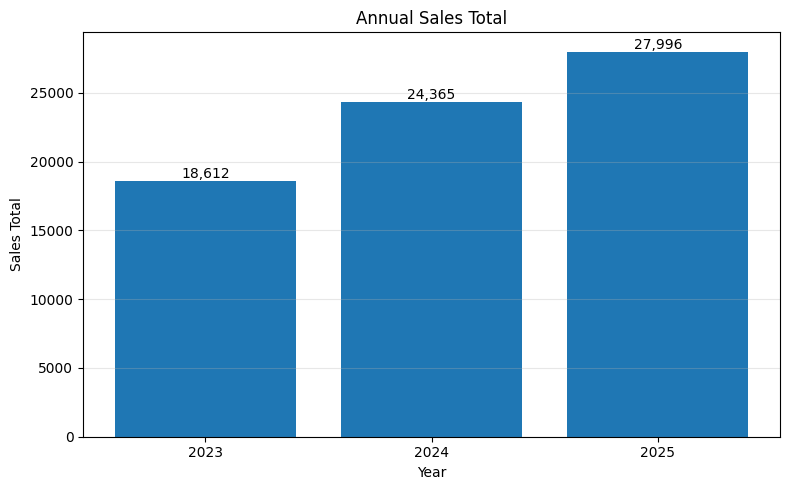

그래프 저장 완료: /content/sample_data/output.png


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


# 파일 경로 설정
input_path = Path("/content/sample_data/input.csv") # 경로 수정
output_path = Path("/content/sample_data/output.png") # 경로 수정


# 1. input.csv 파일을 읽고 Pandas DataFrame 생성
df = pd.read_csv(input_path, encoding="utf-8-sig")

print("원본 데이터 미리보기")
print(df.head())
print()


# 2. 컬럼명의 대소문자와 앞뒤 공백 정리
column_map = {
    column.lower().strip(): column
    for column in df.columns
}

sales_column = column_map.get("sales")
year_column = column_map.get("year")
date_column = column_map.get("date") or column_map.get("data")


# Sales 컬럼이 존재하는지 확인
if sales_column is None:
    raise KeyError("'Sales' 또는 'sales' 컬럼을 찾을 수 없습니다.")


# Year 컬럼이 없으면 날짜 컬럼에서 연도 추출
if year_column is None:
    if date_column is None:
        raise KeyError("'Year' 컬럼 또는 날짜 컬럼을 찾을 수 없습니다.")

    df[date_column] = pd.to_datetime(
        df[date_column],
        errors="raise"
    )

    df["Year"] = df[date_column].dt.year
    year_column = "Year"


# 3. Sales 컬럼 기준 연도별 합계 집계
annual_sales = (
    df.groupby(year_column, as_index=False)[sales_column]
    .sum()
    .rename(
        columns={
            year_column: "Year",
            sales_column: "Sales_Total"
        }
    )
)

print("연도별 판매량 합계")
print(annual_sales)
print()


# 4. Matplotlib으로 막대그래프 생성
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    annual_sales["Year"].astype(str),
    annual_sales["Sales_Total"]
)

ax.set_title("Annual Sales Total")
ax.set_xlabel("Year")
ax.set_ylabel("Sales Total")
ax.grid(axis="y", alpha=0.3)


# 각 막대 위에 판매량 합계 표시
for bar, value in zip(
    bars,
    annual_sales["Sales_Total"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,.0f}",
        ha="center",
        va="bottom"
    )


# 5. 그래프를 output.png로 저장
fig.tight_layout()

fig.savefig(
    output_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(f"그래프 저장 완료: {output_path.resolve()}")

### 코드 상세 설명
이 코드는 `input.csv` 파일에서 판매 데이터를 읽어와 연도별 총 판매량을 집계하고, 이를 막대 그래프로 시각화한 후 `output.png` 파일로 저장합니다. 누락된 'Year' 컬럼은 'Date' 또는 'Data' 컬럼에서 추출합니다.

```python
from pathlib import Path
```
`pathlib` 모듈의 `Path` 클래스를 임포트합니다. 이는 파일 경로를 객체 지향적으로 다루기 위해 사용됩니다.

```python
import matplotlib.pyplot as plt
import pandas as pd
```
- `matplotlib.pyplot`을 `plt`라는 별칭으로 임포트합니다. 이는 데이터를 시각화하는 데 사용되는 파이썬 라이브러리입니다.
- `pandas`를 `pd`라는 별칭으로 임포트합니다. 이는 데이터 처리 및 분석(특히 DataFrame 사용)을 위한 핵심 라이브러리입니다.

```python
# 파일 경로 설정
input_path = Path("input.csv")
output_path = Path("output.png")
```
- `input.csv` 파일을 나타내는 `Path` 객체를 `input_path` 변수에 할당합니다.
- `output.png` 파일을 나타내는 `Path` 객체를 `output_path` 변수에 할당합니다. 시각화된 그래프가 이 파일로 저장됩니다.

```python
# 1. input.csv 파일을 읽고 Pandas DataFrame 생성
df = pd.read_csv(input_path, encoding="utf-8-sig")
```
- `pd.read_csv()` 함수를 사용하여 `input_path`가 가리키는 CSV 파일을 읽어옵니다. `encoding="utf-8-sig"`는 한글 깨짐 방지 및 BOM(Byte Order Mark) 처리를 위해 자주 사용되는 인코딩 방식입니다.
- 읽어온 데이터는 `df`라는 Pandas DataFrame 객체에 저장됩니다.

```python
print("원본 데이터 미리보기")
print(df.head())
print()
```
- `df.head()`를 호출하여 DataFrame `df`의 첫 5행을 출력합니다. 이는 데이터가 제대로 로드되었는지 확인하는 데 유용합니다.

```python
# 2. 컬럼명의 대소문자와 앞뒤 공백 정리
column_map = {
    column.lower().strip(): column
    for column in df.columns
}
```
- DataFrame `df`의 모든 컬럼명을 순회하면서 `lower()`로 소문자로 만들고, `strip()`으로 앞뒤 공백을 제거합니다.
- 이렇게 정리된 이름을 키(key)로, 원본 컬럼명을 값(value)으로 하는 딕셔너리 `column_map`을 생성합니다. 이는 사용자가 대소문자나 공백을 다르게 입력해도 컬럼을 찾을 수 있도록 유연성을 제공합니다.

```python
sales_column = column_map.get("sales")
year_column = column_map.get("year")
date_column = column_map.get("date") or column_map.get("data")
```
- `column_map` 딕셔너리에서 'sales', 'year', 'date', 'data'에 해당하는 원본 컬럼명을 찾아 각각 `sales_column`, `year_column`, `date_column` 변수에 할당합니다.
- `date_column`의 경우, 'date'가 없으면 'data'를 시도합니다.

```python
# Sales 컬럼이 존재하는지 확인
if sales_column is None:
    raise KeyError("'Sales' 또는 'sales' 컬럼을 찾을 수 없습니다.")
```
- `sales_column` 변수가 `None`이면 (즉, 'Sales' 또는 'sales' 컬럼을 찾을 수 없으면) `KeyError`를 발생시켜 사용자에게 알립니다. `sales` 데이터가 없으면 분석을 진행할 수 없기 때문입니다.

```python
# Year 컬럼이 없으면 날짜 컬럼에서 연도 추출
if year_column is None:
    if date_column is None:
        raise KeyError("'Year' 컬럼 또는 날짜 컬럼을 찾을 수 없습니다.")

    df[date_column] = pd.to_datetime(
        df[date_column],
        errors="raise"
    )

    df["Year"] = df[date_column].dt.year
    year_column = "Year"
```
- `year_column`이 `None`인 경우 (즉, 'Year' 컬럼이 없는 경우)에 실행됩니다.
- 먼저 `date_column`도 `None`인지 확인하고, 그렇다면 `KeyError`를 발생시킵니다 (연도를 추출할 수 있는 날짜 컬럼도 없기 때문).
- `pd.to_datetime()` 함수를 사용하여 `date_column`의 데이터를 날짜/시간 형식으로 변환합니다. `errors="raise"`는 변환 중 오류가 발생하면 예외를 발생시킵니다.
- 변환된 날짜/시간 컬럼에서 `.dt.year`를 사용하여 연도만 추출하여 새로운 'Year' 컬럼으로 DataFrame `df`에 추가합니다.
- 이제 `year_column`은 새로 생성된 'Year' 컬럼을 가리키도록 업데이트됩니다.

```python
# 3. Sales 컬럼 기준 연도별 합계 집계
annual_sales = (
    df.groupby(year_column, as_index=False)[sales_column]
    .sum()
    .rename(
        columns={
            year_column: "Year",
            sales_column: "Sales_Total"
        }
    )
)
```
- `df.groupby(year_column, as_index=False)`를 사용하여 `year_column` (예: 'Year')을 기준으로 데이터를 그룹화합니다. `as_index=False`는 그룹화 컬럼을 인덱스가 아닌 일반 컬럼으로 유지합니다.
- 그룹화된 데이터에서 `sales_column` (예: 'Sales')만 선택하여 `sum()` 함수로 각 연도별 판매량의 합계를 계산합니다.
- `rename()` 함수를 사용하여 그룹화된 결과 DataFrame의 컬럼명을 `year_column`은 'Year'로, `sales_column`은 'Sales_Total'로 변경합니다.
- 최종 결과는 `annual_sales` DataFrame에 저장됩니다.

```python
print("연도별 판매량 합계")
print(annual_sales)
print()
```
- 연도별 판매량 합계가 담긴 `annual_sales` DataFrame을 출력하여 확인합니다.

```python
# 4. Matplotlib으로 막대그래프 생성
fig, ax = plt.subplots(figsize=(8, 5))
```
- `plt.subplots()`를 사용하여 새로운 Matplotlib 그림(figure)과 축(axes) 객체를 생성합니다. `figsize=(8, 5)`는 그림의 크기를 너비 8인치, 높이 5인치로 설정합니다.
- `fig`는 전체 그림을, `ax`는 그래프를 그릴 좌표 평면을 나타냅니다.

```python
bars = ax.bar(
    annual_sales["Year"].astype(str),
    annual_sales["Sales_Total"]
)
```
- `ax.bar()` 함수를 사용하여 막대 그래프를 생성합니다.
- x축은 `annual_sales["Year"]` 컬럼의 값을 문자열로 변환한 값(`astype(str)`)을 사용합니다. 이는 연도를 범주형으로 처리하여 막대 그래프가 개별 연도를 나타내도록 합니다.
- y축은 `annual_sales["Sales_Total"]` 컬럼의 값을 사용합니다.
- 생성된 막대 객체들은 `bars` 변수에 저장됩니다.

```python
ax.set_title("Annual Sales Total")
ax.set_xlabel("Year")
ax.set_ylabel("Sales Total")
ax.grid(axis="y", alpha=0.3)
```
- `ax.set_title()`로 그래프의 제목을 'Annual Sales Total'로 설정합니다.
- `ax.set_xlabel()`로 x축 레이블을 'Year'로 설정합니다.
- `ax.set_ylabel()`로 y축 레이블을 'Sales Total'로 설정합니다.
- `ax.grid(axis="y", alpha=0.3)`로 y축에만 연한 그리드 라인을 추가하여 가독성을 높입니다.

```python
# 각 막대 위에 판매량 합계 표시
for bar, value in zip(
    bars,
    annual_sales["Sales_Total"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,.0f}",
        ha="center",
        va="bottom"
    )
```
- `zip(bars, annual_sales["Sales_Total"])`를 사용하여 각 막대(`bar`)와 해당 판매 총액(`value`)을 함께 순회합니다.
- `ax.text()` 함수를 사용하여 각 막대 위에 판매 총액을 텍스트로 표시합니다.
  - `bar.get_x() + bar.get_width() / 2`: 텍스트를 막대의 중앙에 위치시킵니다.
  - `bar.get_height()`: 텍스트를 막대의 맨 위에 위치시킵니다.
  - `f"{value:,.0f}"`: `value`를 천 단위 구분 기호가 있는 정수 형식으로 포맷합니다.
  - `ha="center"`: 텍스트를 수평으로 중앙 정렬합니다.
  - `va="bottom"`: 텍스트를 수직으로 막대 위에 위치시킵니다 (막대 높이를 기준으로 아래쪽).

```python
# 5. 그래프를 output.png로 저장
fig.tight_layout()
```
- `fig.tight_layout()`는 그래프 요소들(제목, 레이블 등)이 겹치지 않도록 자동으로 조정하여 레이아웃을 최적화합니다.

```python
fig.savefig(
    output_path,
    dpi=150,
    bbox_inches="tight"
)
```
- `fig.savefig()`를 사용하여 현재 그림(`fig`)을 `output_path` (즉, `output.png`)에 파일로 저장합니다.
  - `dpi=150`: 저장될 이미지의 해상도를 150 DPI로 설정합니다.
  - `bbox_inches="tight"`: 그림의 여백을 최소화하여 실제 내용만 저장되도록 합니다.

```python
plt.show()
plt.close(fig)
```
- `plt.show()`는 현재 생성된 그래프를 화면에 표시합니다.
- `plt.close(fig)`는 메모리에서 현재 그림(`fig`)을 닫아 리소스를 해제합니다. 특히 반복적인 플로팅 작업 시 메모리 누수를 방지하는 데 좋습니다.

```python
print(f"그래프 저장 완료: {output_path.resolve()}")
```
- 그래프가 저장된 파일의 전체 경로를 출력하여 사용자에게 확인 메시지를 제공합니다. `output_path.resolve()`는 `Path` 객체의 절대 경로를 반환합니다.

In [ ]:
# 고객 문의 유형별 키워드
CATEGORY_KEYWORDS = {
    "배송": [
        "배송", "도착", "언제 오", "택배", "송장",
        "운송장", "배달", "출고", "배송비"
    ],
    "환불": [
        "환불", "돈을 돌려", "결제 취소", "구매 취소",
        "주문 취소", "반품", "취소하고 싶"
    ],
    "교환": [
        "교환", "바꾸고", "바꿔", "다른 크기",
        "다른 사이즈", "다른 색상", "사이즈 변경"
    ],
    "상품 문의": [
        "상품", "제품", "재고", "가격", "사이즈",
        "색상", "기능", "사용법", "소재", "원산지"
    ]
}


# 문의 유형별 추천 답변
RECOMMENDED_ANSWERS = {
    "배송": (
        "배송 상태를 확인해 드리겠습니다. "
        "주문번호를 알려주세요."
    ),
    "환불": (
        "환불 절차를 안내해 드리겠습니다. "
        "주문번호와 환불 사유를 알려주세요."
    ),
    "교환": (
        "교환 가능 여부를 확인해 드리겠습니다. "
        "주문번호와 교환을 원하는 상품 정보를 알려주세요."
    ),
    "상품 문의": (
        "상품 정보를 확인해 드리겠습니다. "
        "궁금한 상품명과 문의 내용을 자세히 알려주세요."
    ),
    "기타": (
        "문의 내용을 정확히 분류하기 어렵습니다. "
        "조금 더 자세하게 설명해 주세요."
    )
}


def normalize_text(text):
    """
    입력 문장을 비교하기 쉬운 형태로 정리합니다.
    문자열이 아니거나 비어 있으면 빈 문자열을 반환합니다.
    """
    if not isinstance(text, str):
        return ""

    return text.strip().lower()


def count_keywords(text, keywords):
    """
    문장에 포함된 키워드의 개수를 계산합니다.
    """
    count = 0

    for keyword in keywords:
        if keyword in text:
            count += 1

    return count


def classify_inquiry(inquiry):
    """
    고객 문의를 배송, 환불, 교환, 상품 문의, 기타 중 하나로 분류합니다.
    """
    text = normalize_text(inquiry)

    # 입력값이 없으면 기타로 처리
    if not text:
        return "기타"

    category_scores = {}

    # 유형별로 포함된 키워드 개수 계산
    for category, keywords in CATEGORY_KEYWORDS.items():
        category_scores[category] = count_keywords(text, keywords)

    # 가장 높은 점수를 받은 유형 선택
    best_category = max(category_scores, key=category_scores.get)
    best_score = category_scores[best_category]

    # 일치하는 키워드가 없으면 기타로 처리
    if best_score == 0:
        return "기타"

    return best_category


def get_recommended_answer(category):
    """
    분류된 유형에 맞는 추천 답변을 반환합니다.
    등록되지 않은 유형은 기타 답변으로 처리합니다.
    """
    return RECOMMENDED_ANSWERS.get(
        category,
        RECOMMENDED_ANSWERS["기타"]
    )


def process_inquiry(inquiry):
    """
    문의를 분류하고 결과와 추천 답변을 함께 반환합니다.
    """
    try:
        category = classify_inquiry(inquiry)
        answer = get_recommended_answer(category)

        return {
            "inquiry": inquiry,
            "category": category,
            "recommended_answer": answer
        }

    except Exception:
        # 예상하지 못한 오류도 기타로 처리
        return {
            "inquiry": inquiry,
            "category": "기타",
            "recommended_answer": RECOMMENDED_ANSWERS["기타"]
        }


def print_result(result):
    """
    처리 결과를 보기 좋게 출력합니다.
    """
    print(f"문의 내용: {result['inquiry']}")
    print(f"분류 결과: {result['category']}")
    print(f"추천 답변: {result['recommended_answer']}")


def run_tests():
    """
    5개의 테스트 문장을 실행합니다.
    """
    test_inquiries = [
        "상품이 언제 도착하나요?",
        "환불받고 싶어요.",
        "다른 크기로 바꾸고 싶어요.",
        "이 제품은 현재 재고가 있나요?",
        "회원 탈퇴는 어떻게 하나요?"
    ]

    print("===== 테스트 시작 =====")

    for number, inquiry in enumerate(test_inquiries, start=1):
        print(f"\n[테스트 {number}]")
        result = process_inquiry(inquiry)
        print_result(result)

    print("\n===== 테스트 종료 =====")


def main():
    """
    사용자에게 직접 문의를 입력받습니다.
    """
    print("\n===== 고객 문의 자동 분류 =====")

    try:
        inquiry = input("고객 문의를 입력하세요: ")
        result = process_inquiry(inquiry)

        print()
        print_result(result)

    except (EOFError, KeyboardInterrupt):
        print("\n입력이 중단되었습니다.")
        result = process_inquiry("")
        print_result(result)


if __name__ == "__main__":
    run_tests()
    main()

===== 테스트 시작 =====

[테스트 1]
문의 내용: 상품이 언제 도착하나요?
분류 결과: 배송
추천 답변: 배송 상태를 확인해 드리겠습니다. 주문번호를 알려주세요.

[테스트 2]
문의 내용: 환불받고 싶어요.
분류 결과: 환불
추천 답변: 환불 절차를 안내해 드리겠습니다. 주문번호와 환불 사유를 알려주세요.

[테스트 3]
문의 내용: 다른 크기로 바꾸고 싶어요.
분류 결과: 교환
추천 답변: 교환 가능 여부를 확인해 드리겠습니다. 주문번호와 교환을 원하는 상품 정보를 알려주세요.

[테스트 4]
문의 내용: 이 제품은 현재 재고가 있나요?
분류 결과: 상품 문의
추천 답변: 상품 정보를 확인해 드리겠습니다. 궁금한 상품명과 문의 내용을 자세히 알려주세요.

[테스트 5]
문의 내용: 회원 탈퇴는 어떻게 하나요?
분류 결과: 기타
추천 답변: 문의 내용을 정확히 분류하기 어렵습니다. 조금 더 자세하게 설명해 주세요.

===== 테스트 종료 =====

===== 고객 문의 자동 분류 =====
고객 문의를 입력하세요: 예고된 할인 판매 및 포토카드 사은품 이벤트는 언제부터 언제까지 하나요?

문의 내용: 예고된 할인 판매 및 포토카드 사은품 이벤트는 언제부터 언제까지 하나요?
분류 결과: 기타
추천 답변: 문의 내용을 정확히 분류하기 어렵습니다. 조금 더 자세하게 설명해 주세요.


### 고객 문의 자동 분류 코드 상세 설명

이 코드는 미리 정의된 키워드를 바탕으로 사용자의 문의 내용을 분석하여 카테고리를 분류하고, 그에 맞는 답변을 추천해 주는 시스템입니다.

```python
CATEGORY_KEYWORDS = {
    "배송": ["배송", "도착", ...],
    "환불": [...],
    ...
}
```
각 문의 유형(배송, 환불, 교환, 상품 문의)에 해당하는 핵심 키워드들을 리스트 형태로 정의한 딕셔너리입니다. 분류 시 이 단어들이 포함되어 있는지를 확인합니다.

```python
RECOMMENDED_ANSWERS = {
    "배송": "배송 상태를 확인해 드리겠습니다...",
    ...
    "기타": "...조금 더 자세하게 설명해 주세요."
}
```
분류된 각 카테고리에 대해 사용자에게 보여줄 표준 답변 문구들을 정의한 딕셔너리입니다.

```python
def normalize_text(text):
    if not isinstance(text, str):
        return ""
    return text.strip().lower()
```
입력받은 텍스트를 전처리하는 함수입니다. 문자열 여부를 확인하고, 앞뒤 공백 제거 및 소문자 변환을 통해 비교하기 쉬운 상태로 만듭니다.

```python
def count_keywords(text, keywords):
    count = 0
    for keyword in keywords:
        if keyword in text:
            count += 1
    return count
```
특정 문의 내용(`text`) 안에 해당 카테고리의 키워드(`keywords`)가 몇 개나 포함되어 있는지 개수를 세어 점수를 계산합니다.

```python
def classify_inquiry(inquiry):
    ...
    category_scores = {}
    for category, keywords in CATEGORY_KEYWORDS.items():
        category_scores[category] = count_keywords(text, keywords)
    best_category = max(category_scores, key=category_scores.get)
    ...
```
문의 내용을 분류하는 핵심 함수입니다. 모든 카테고리에 대해 키워드 일치 점수를 계산한 뒤, 가장 높은 점수를 받은 카테고리를 선택합니다. 만약 일치하는 키워드가 하나도 없다면 '기타'로 분류합니다.

```python
def process_inquiry(inquiry):
    try:
        category = classify_inquiry(inquiry)
        answer = get_recommended_answer(category)
        return {"inquiry": inquiry, "category": category, "recommended_answer": answer}
    except Exception:
        ...
```
분류 작업과 답변 추출 작업을 하나로 묶어 처리하는 함수입니다. 예외 상황(에러)이 발생하더라도 프로그램이 멈추지 않고 '기타' 답변을 반환하도록 예외 처리가 되어 있습니다.

```python
def run_tests():
    test_inquiries = [...]
    for number, inquiry in enumerate(test_inquiries, start=1):
        result = process_inquiry(inquiry)
        print_result(result)
```
미리 정의된 5가지 시나리오 문장을 통해 시스템이 정상적으로 분류하고 답변하는지 확인하는 테스트 함수입니다.

```python
def main():
    inquiry = input("고객 문의를 입력하세요: ")
    result = process_inquiry(inquiry)
    print_result(result)
```
실제로 사용자로부터 키보드 입력을 받아 문의 사항을 즉시 분류하고 결과를 출력하는 메인 실행 함수입니다.

In [ ]:
# 세 글자 끝말잇기 게임

# 한글 음절을 구성하는 초성, 중성, 종성
CHOSEONG = [
    "ㄱ", "ㄲ", "ㄴ", "ㄷ", "ㄸ", "ㄹ", "ㅁ",
    "ㅂ", "ㅃ", "ㅅ", "ㅆ", "ㅇ", "ㅈ", "ㅉ",
    "ㅊ", "ㅋ", "ㅌ", "ㅍ", "ㅎ"
]

JUNGSEONG = [
    "ㅏ", "ㅐ", "ㅑ", "ㅒ", "ㅓ", "ㅔ", "ㅕ",
    "ㅖ", "ㅗ", "ㅘ", "ㅙ", "ㅚ", "ㅛ", "ㅜ",
    "ㅝ", "ㅞ", "ㅟ", "ㅠ", "ㅡ", "ㅢ", "ㅣ"
]

JONGSEONG = [
    "", "ㄱ", "ㄲ", "ㄳ", "ㄴ", "ㄵ", "ㄶ",
    "ㄷ", "ㄹ", "ㄺ", "ㄻ", "ㄼ", "ㄽ", "ㄾ",
    "ㄿ", "ㅀ", "ㅁ", "ㅂ", "ㅄ", "ㅅ", "ㅆ",
    "ㅇ", "ㅈ", "ㅊ", "ㅋ", "ㅌ", "ㅍ", "ㅎ"
]


def is_hangul_syllable(char):
    """
    글자가 완성형 한글 음절인지 확인합니다.
    예: 가, 나, 한 → True
    """
    return len(char) == 1 and "가" <= char <= "힣"


def split_hangul(char):
    """
    한글 한 글자를 초성, 중성, 종성 번호로 분리합니다.

    예:
    '력' → 초성 ㄹ, 중성 ㅕ, 종성 ㄱ
    """
    code = ord(char) - ord("가")

    choseong_index = code // (21 * 28)
    jungseong_index = (code % (21 * 28)) // 28
    jongseong_index = code % 28

    return choseong_index, jungseong_index, jongseong_index


def combine_hangul(choseong_index, jungseong_index, jongseong_index):
    """
    초성, 중성, 종성 번호를 한글 한 글자로 합칩니다.
    """
    code = (
        ord("가")
        + choseong_index * 21 * 28
        + jungseong_index * 28
        + jongseong_index
    )

    return chr(code)


def apply_initial_sound_rule(char):
    """
    두음법칙을 적용한 글자를 반환합니다.

    주요 규칙:
    1. ㄹ + 야/여/요/유/이/예 계열 → ㅇ
       예: 력 → 역, 류 → 유, 리 → 이

    2. 그 밖의 ㄹ 계열 → ㄴ
       예: 락 → 낙, 로 → 노

    3. ㄴ + 야/여/요/유/이/예 계열 → ㅇ
       예: 녀 → 여, 년 → 연
    """
    if not is_hangul_syllable(char):
        return char

    cho, jung, jong = split_hangul(char)

    initial = CHOSEONG[cho]
    vowel = JUNGSEONG[jung]

    special_vowels = {"ㅑ", "ㅕ", "ㅛ", "ㅠ", "ㅣ", "ㅖ"}

    # ㄹ 두음법칙
    if initial == "ㄹ":
        if vowel in special_vowels:
            new_initial = "ㅇ"
        else:
            new_initial = "ㄴ"

    # ㄴ 두음법칙
    elif initial == "ㄴ" and vowel in special_vowels:
        new_initial = "ㅇ"

    else:
        return char

    new_cho = CHOSEONG.index(new_initial)

    return combine_hangul(new_cho, jung, jong)


def get_allowed_first_characters(last_char):
    """
    다음 단어의 첫 글자로 사용할 수 있는 글자들을 반환합니다.

    예:
    '력' → {'력', '역'}
    '락' → {'락', '낙'}
    '녀' → {'녀', '여'}
    """
    allowed_characters = {last_char}
    changed_char = apply_initial_sound_rule(last_char)

    allowed_characters.add(changed_char)

    return allowed_characters


def check_word(word, used_words, previous_word):
    """
    입력한 단어가 규칙에 맞는지 검사합니다.

    반환값:
    - 성공 여부
    - 결과 메시지
    """
    # 세 글자인지 검사
    if len(word) != 3:
        return False, "세 글자 단어가 아닙니다."

    # 이미 사용한 단어인지 검사
    if word in used_words:
        return False, "이미 사용한 단어입니다."

    # 첫 번째 단어는 끝말 연결 검사를 하지 않음
    if previous_word is None:
        return True, "첫 번째 단어가 등록되었습니다."

    previous_last_char = previous_word[-1]
    current_first_char = word[0]

    allowed_characters = get_allowed_first_characters(previous_last_char)

    if current_first_char not in allowed_characters:
        allowed_text = ", ".join(sorted(allowed_characters))

        return (
            False,
            f"'{previous_last_char}' 또는 두음법칙이 적용된 "
            f"'{allowed_text}'으로 시작해야 합니다."
        )

    return True, "올바른 단어입니다."


def print_bad_ending(reason):
    """
    실패했을 때 배드 엔딩을 출력합니다.
    """
    print("\n" + "=" * 40)
    print("💀 배드 엔딩")
    print(f"실패 이유: {reason}")
    print("끝말잇기 게임이 종료되었습니다.")
    print("=" * 40)


def print_good_ending(used_words):
    """
    10개의 단어를 연속으로 성공했을 때 굿 엔딩을 출력합니다.
    """
    print("\n" + "=" * 40)
    print("🎉 굿 엔딩")
    print("축하합니다! 10연속 끝말잇기에 성공했습니다!")
    print(" → ".join(used_words))
    print("=" * 40)


def play_game():
    """
    끝말잇기 게임의 전체 진행을 담당합니다.
    """
    used_words = []
    previous_word = None
    target_count = 10

    print("=" * 40)
    print("세 글자 끝말잇기 게임")
    print("=" * 40)
    print("규칙")
    print("1. 반드시 세 글자 단어를 입력합니다.")
    print("2. 같은 단어는 다시 사용할 수 없습니다.")
    print("3. 두음법칙을 인정합니다.")
    print("4. 10개의 단어를 연속으로 성공하면 승리합니다.")
    print("=" * 40)

    while len(used_words) < target_count:
        current_count = len(used_words) + 1

        if previous_word is None:
            prompt = f"\n[{current_count}/{target_count}] 첫 단어 입력: "

        else:
            last_char = previous_word[-1]
            allowed = get_allowed_first_characters(last_char)
            allowed_text = " 또는 ".join(sorted(allowed))

            prompt = (
                f"\n[{current_count}/{target_count}] "
                f"'{allowed_text}'으로 시작하는 단어 입력: "
            )

        try:
            word = input(prompt).strip()

        except (EOFError, KeyboardInterrupt):
            print_bad_ending("입력이 중단되었습니다.")
            return

        is_valid, message = check_word(
            word=word,
            used_words=used_words,
            previous_word=previous_word
        )

        if not is_valid:
            print_bad_ending(message)
            return

        used_words.append(word)
        previous_word = word

        print(f"✅ 성공: {word}")
        print(f"현재 연속 성공: {len(used_words)}회")

    print_good_ending(used_words)


if __name__ == "__main__":
    play_game()

세 글자 끝말잇기 게임
규칙
1. 반드시 세 글자 단어를 입력합니다.
2. 같은 단어는 다시 사용할 수 없습니다.
3. 두음법칙을 인정합니다.
4. 10개의 단어를 연속으로 성공하면 승리합니다.

[1/10] 첫 단어 입력: 파이썬
✅ 성공: 파이썬
현재 연속 성공: 1회

[2/10] '썬'으로 시작하는 단어 입력: 썬크림
✅ 성공: 썬크림
현재 연속 성공: 2회

[3/10] '림 또는 임'으로 시작하는 단어 입력: 임창정
✅ 성공: 임창정
현재 연속 성공: 3회

[4/10] '정'으로 시작하는 단어 입력: 정발산
✅ 성공: 정발산
현재 연속 성공: 4회

[5/10] '산'으로 시작하는 단어 입력: 산중턱
✅ 성공: 산중턱
현재 연속 성공: 5회

[6/10] '턱'으로 시작하는 단어 입력: 턱시도
✅ 성공: 턱시도
현재 연속 성공: 6회

[7/10] '도'으로 시작하는 단어 입력: 도메인
✅ 성공: 도메인
현재 연속 성공: 7회

[8/10] '인'으로 시작하는 단어 입력: 인사돌
✅ 성공: 인사돌
현재 연속 성공: 8회

[9/10] '돌'으로 시작하는 단어 입력: 돌멩이
✅ 성공: 돌멩이
현재 연속 성공: 9회

[10/10] '이'으로 시작하는 단어 입력: 이리듐
✅ 성공: 이리듐
현재 연속 성공: 10회

🎉 굿 엔딩
축하합니다! 10연속 끝말잇기에 성공했습니다!
파이썬 → 썬크림 → 임창정 → 정발산 → 산중턱 → 턱시도 → 도메인 → 인사돌 → 돌멩이 → 이리듐


### 세 글자 끝말잇기 게임 코드 상세 설명

이 코드는 한글 음절의 구성 원리를 이용하여 두음법칙이 적용된 끝말잇기 규칙을 구현한 게임입니다. 사용자가 입력한 단어가 세 글자인지, 중복되지는 않았는지, 그리고 이전 단어의 끝자리와 이어지는지를 검사합니다.

```python
CHOSEONG = [...]
JUNGSEONG = [...]
JONGSEONG = [...]
```
한글을 유니코드로 조합하거나 분리하기 위해 필요한 초성(19개), 중성(21개), 종성(28개, 공백 포함) 리스트입니다. 한글 음절은 이 세 가지 요소의 조합으로 만들어집니다.

```python
def is_hangul_syllable(char):
    return len(char) == 1 and "가" <= char <= "힣"
```
입력받은 한 글자가 '가'부터 '힣' 사이의 완성형 한글 음절인지 확인하는 함수입니다.

```python
def split_hangul(char):
    code = ord(char) - ord("가")
    ...
    return choseong_index, jungseong_index, jongseong_index
```
한글 한 글자를 유니코드 공식에 따라 초성, 중성, 종성의 인덱스로 분리합니다. 예를 들어 '력'을 입력하면 각 리스트에서 'ㄹ', 'ㅕ', 'ㄱ'에 해당하는 번호를 찾아줍니다.

```python
def apply_initial_sound_rule(char):
    ...
    # ㄹ 두음법칙, ㄴ 두음법칙 처리
```
한국어의 두음법칙을 구현한 핵심 함수입니다. '력'이 '역'으로, '로'가 '노'로, '녀'가 '여'로 변하는 규칙을 적용하여 반환합니다.

```python
def check_word(word, used_words, previous_word):
    if len(word) != 3: ...
    if word in used_words: ...
    ...
```
사용자가 입력한 단어가 게임 규칙에 맞는지 검사합니다. 세 글자 여부, 중복 여부, 그리고 이전 단어의 마지막 글자와 (두음법칙 포함) 일치하는지를 확인합니다.

```python
def play_game():
    while len(used_words) < target_count:
        ...
```
게임의 전체 흐름을 제어하는 함수입니다. 사용자로부터 입력을 받고, 결과를 검증하며, 10번 연속 성공 시 굿 엔딩을, 실패 시 배드 엔딩을 출력합니다.